In [7]:
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib
import matplotlib.pyplot as plt


In [8]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


In [9]:
import shap

In [10]:
# Load the scaled regression data
data = joblib.load("preprocessed_regression.pkl")

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

# Load the best Linear Regression model 
model = joblib.load("models/best_regression_model.pkl")

print("Model:", type(model).__name__)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Model: RandomForestRegressor
X_train: (171, 15)
X_test: (43, 15)


c:\Users\ThinkPad\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ThinkPad\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [13]:
masker = shap.maskers.Independent(X_train, max_samples=len(X_train))

explainer = shap.TreeExplainer(model, masker)

shap_values = explainer.shap_values( X_test)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (43, 15)


True score: 1340000000
Predicted score: 1286607190.5131047


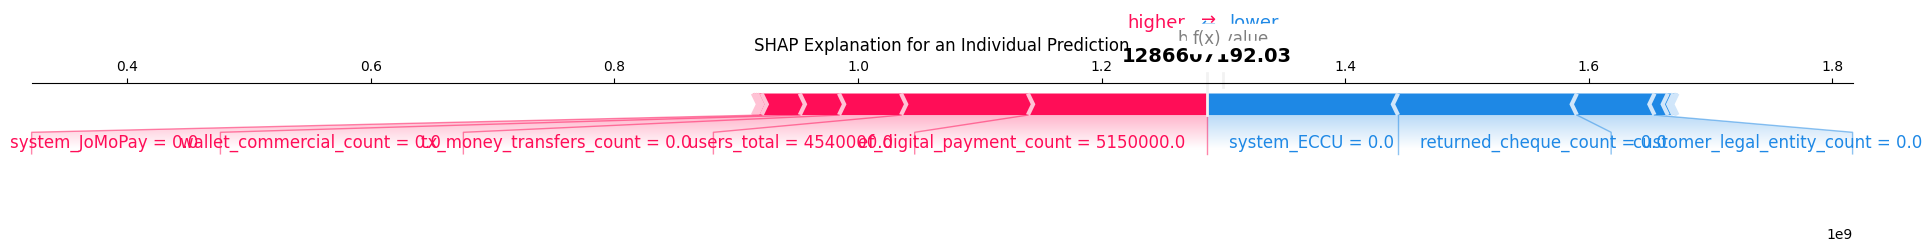

In [14]:
sample_index = 0  
sample=X_test[sample_index:sample_index+1]

print("True score:", y_test.iloc[sample_index])
print("Predicted score:", model.predict(sample)[0])

# Extract the base value
base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])
shap.force_plot(
    base_value,
    shap_values[sample_index],
    sample.iloc[0],
    feature_names=X_test.columns.tolist(),
    matplotlib=True,
    show=False
)

plt.title("SHAP Explanation for an Individual Prediction")

plt.tight_layout()
plt.show()

In [15]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [16]:
shap_table = pd.DataFrame({"Feature": X_test.columns, "Input Value": (sample.iloc[0].values), "SHAP Value": (shap_values[sample_index])})


shap_table["Impact"] = np.where(shap_table["SHAP Value"] > 0, "Increased prediction", np.where(
        shap_table["SHAP Value"] < 0,
        "Reduced prediction",
        "No impact"
    )
)


shap_table["Absolute Impact"] = (shap_table["SHAP Value"].abs())


shap_table = shap_table.sort_values(by="Absolute Impact", ascending=False).reset_index(drop=True)


display(
    shap_table[
        [
            "Feature",
            "Input Value",
            "SHAP Value",
            "Impact"
        ]
    ]
)

,Feature,Input Value,SHAP Value,Impact
0,system_ECCU,0,-1.567775e+08,Reduced prediction
1,ef_digital_payment_count,5150000,1.471828e+08,Increased prediction
2,returned_cheque_count,0,-1.468251e+08,Reduced prediction
3,users_total,4540000,1.041326e+08,Increased prediction
4,customer_legal_entity_count,0,-6.375996e+07,Reduced prediction
5,tx_money_transfers_count,0,5.095950e+07,Increased prediction
6,wallet_commercial_count,0,3.221715e+07,Increased prediction
7,system_JoMoPay,0,3.129579e+07,Increased prediction
8,transactions_total,6430000,-1.094486e+07,Reduced prediction
9,ach_jod_transaction_count,0,-4.480753e+06,Reduced prediction


In [17]:
print("Features that increased the prediction:")

display(
    shap_table[
        shap_table["SHAP Value"] > 0
    ][
        [
            "Feature",
            "Input Value",
            "SHAP Value"
        ]
    ].head(5)
)


print("Features that reduced the prediction:")

display(
    shap_table[
        shap_table["SHAP Value"] < 0
    ][
        [
            "Feature",
            "Input Value",
            "SHAP Value"
        ]
    ].head(5)
)

Features that increased the prediction:


,Feature,Input Value,SHAP Value
1,ef_digital_payment_count,5150000,1.471828e+08
3,users_total,4540000,1.041326e+08
5,tx_money_transfers_count,0,5.095950e+07
6,wallet_commercial_count,0,3.221715e+07
7,system_JoMoPay,0,3.129579e+07


Features that reduced the prediction:


,Feature,Input Value,SHAP Value
0,system_ECCU,0,-1.567775e+08
2,returned_cheque_count,0,-1.468251e+08
4,customer_legal_entity_count,0,-6.375996e+07
8,transactions_total,6430000,-1.094486e+07
9,ach_jod_transaction_count,0,-4.480753e+06


In [18]:
total_shap_effect = float(shap_values[sample_index].sum())

reconstructed_prediction = (base_value + total_shap_effect)

print(f"Base value: {base_value:,.2f} JOD")

print(f"Total SHAP effect: {total_shap_effect:,.2f} JOD")

print(f"SHAP reconstructed prediction: {reconstructed_prediction:,.2f} JOD")

print(f"Original model prediction: {model.predict(sample)[0]:,.2f} JOD")

Base value: 1,299,786,939.51 JOD
Total SHAP effect: -13,179,747.48 JOD
SHAP reconstructed prediction: 1,286,607,192.03 JOD
Original model prediction: 1,286,607,190.51 JOD


In [19]:
#Using joblib save the shap explainer

joblib.dump(
    explainer,
    "models/regression_shap_explainer.pkl"
)


print(
    "SHAP explainer saved to: "
    "models/regression_shap_explainer.pkl"
)

SHAP explainer saved to: models/regression_shap_explainer.pkl
